# 01 · Dataset familiarisation, cleaning and sampling effort

**Author:** Yike SHI

**Martinique Breeding Bird Monitoring, 2012–2025 — Applied Statistics final project**

This notebook answers **Question 1** of the brief (dataset structure, descriptive statistics,
observation effort across time and space, data quality). It also builds the clean tables
(`data/processed/`) that notebooks 02–04 use.

All heavy logic lives in `src/` (`load.py` → `clean.py` → `effort.py`); this notebook calls it,
checks every step, and explains the decisions.

*Time unit.* Surveys take place once a year, in the breeding season (mostly April–May, some visits in late March and June), with two visits
(passages) per transect. "Year" therefore always means one annual survey: 2014–2025 gives 12 years.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src import config as C, load, clean, effort, plots

plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
rng = np.random.default_rng(C.SEED)
print("Project root:", ROOT.name, "| raw file exists:", C.RAW_XLSX.exists())

Project root: birds_project_statistic | raw file exists: True


## 1. Workbook structure

The workbook has three sheets. `pd.read_excel` reads only the first sheet by default, so each
sheet is read explicitly by name. None of them has a clean one-row header:

* **`NOM FRANÇAIS`** (observation log) has a **three-row header** (variable / distance band /
  detection mode). We skip it and assign English names (`config.OBS_COLUMNS`).
* **`ESPECES`** (species list) has no header at all and two empty leading columns.
* **`GPS-MILIEU`** (point catalogue) has a CRS label row and a partial header.

In [2]:
obs_raw = load.load_observations()
species_raw = load.load_species()
sites_raw = load.load_sites()

pd.DataFrame({
    "sheet": [C.SHEET_OBS, C.SHEET_SPECIES, C.SHEET_SITES],
    "role": ["observation log (fact table)", "species list", "point catalogue"],
    "rows": [len(obs_raw), len(species_raw), len(sites_raw)],
    "columns used": [obs_raw.shape[1] - 1, species_raw.shape[1], sites_raw.shape[1]],
})

,sheet,role,rows,columns used
0,NOM FRANÇAIS,observation log (fact table),114495,26
1,ESPECES,species list,87,3
2,GPS-MILIEU,point catalogue,650,6


### Column dictionary of the observation log

One row of the log = **one species detected at one point during one visit**. Counts are split
by distance band (<25 m, 25–50 m, 50–100 m, >100 m) × detection mode (heard / seen), plus
fly-overs. The weather codes have no codebook in the workbook; the meaning below follows the
French STOC-EPS protocol on which this survey is modelled, and is an **assumption**.

In [3]:
meaning = {
    "observer_raw": "observer name (free text)", "dept": "French department code (972 = Martinique)",
    "transect_raw": "transect (site) name", "date_raw": "visit date", "passage_raw": "visit number within the year (1 or 2)",
    "clouds": "cloud cover, 1-3 (0-33 / 33-66 / 66-100 %)", "rain": "rain, 1-3 (none / drizzle / showers)",
    "wind": "wind, 1-3 (none / light / moderate-strong)", "visibility": "visibility, 1-3 (good / moderate / poor)",
    "point": "point number along the transect (1-10)", "start_time": "start time of the 5-min point count",
    "species_raw": "species (French common name)", "flight": "individuals flying over (not using the site)",
    "note": "free-text remark (mentoring, habitat notes)",
}
for c in C.DETAIL_COLS:
    meaning[c] = f"individuals {'heard' if c.startswith('aud') else 'seen'}, band {c.split('_', 1)[1]}"
for c in ["xls_total_aud", "xls_total_vis", "xls_total_av", "xls_total_av_flight"]:
    meaning[c] = "workbook total (formula) - NOT used, recomputed from cells"
coldict = pd.DataFrame({"english_name": list(C.OBS_COLUMNS),
                        "french_header": list(C.OBS_COLUMNS.values()),
                        "meaning": [meaning[c] for c in C.OBS_COLUMNS]})
coldict.to_csv(C.RES_DIR / "table01_column_dictionary.csv", index=False)
coldict

,english_name,french_header,meaning
0,observer_raw,Nom observateur,observer name (free text)
1,dept,code département,French department code (972 = Martinique)
2,transect_raw,Nom transect,transect (site) name
3,date_raw,date,visit date
4,passage_raw,"1er, 2e ou 3e passage",visit number within the year (1 or 2)
5,clouds,nuages,"cloud cover, 1-3 (0-33 / 33-66 / 66-100 %)"
6,rain,pluie,"rain, 1-3 (none / drizzle / showers)"
7,wind,vent,"wind, 1-3 (none / light / moderate-strong)"
8,visibility,visibilité,"visibility, 1-3 (good / moderate / poor)"
9,point,N° point,point number along the transect (1-10)


### Time coverage: there are no 2012–2013 observations

The observation log starts on **29 March 2014** (no 2012–2013 records), so the 2014–2025 trend
window uses the full record.

In [4]:
d = pd.to_datetime(obs_raw["date_raw"])
print("First date:", d.min().date(), "| last date:", d.max().date())
print("Rows per year:")
print(d.dt.year.value_counts().sort_index().to_string())
print("\nRows per month:", d.dt.month.value_counts().sort_index().to_dict())

First date: 2014-03-29 | last date: 2025-07-03
Rows per year:
date_raw
2014     5378
2015     8162
2016    11011
2017     9228
2018     9733
2019     9572
2020     9956
2021    10604
2022    10804
2023    10224
2024    10051
2025     9772

Rows per month: {3: 221, 4: 47791, 5: 49066, 6: 17414, 7: 3}


## 2. Data-quality audit and cleaning

A raw audit revealed several data-entry problems. Each is handled by a documented rule in
`src/clean.py`; the table below is the complete, auditable log of what was changed.

Key decisions (the "why"):

1. **Name harmonisation** — transects and observers appear under several spellings
   ('BORELIE' / 'Borelie', 'MARTIN Anne' / 'Anne MARTIN'). Treating them as different
   entities would inflate the number of sites/observers and break the panel structure.
2. **Double-entered visits** — in 25 visits (mostly 2016) about 50 % of rows are exact
   duplicates: the whole visit was typed twice. Keeping them would double effort *and* counts
   for those visits and create a spurious 2016 peak. Isolated duplicates elsewhere could be two
   genuine identical contacts, so they are kept and flagged.
3. **One visit = one date** — by protocol a transect is visited twice per year (passages 1
   and 2), each time covering points 1–10 in one morning. We repair drag-filled dates, swapped
   passage labels and visit fragments recorded on another day (rules documented in
   `clean.reconcile_visits`).
4. **Counts recomputed from the distance cells** — the workbook's total columns are broken
   formulas in a few dozen rows (zeros or fractions where cells hold birds), so the eight
   primary cells are summed instead.
5. **Taxonomy** — records identified only to genus/family (mostly unidentified hummingbirds,
   'Trochilidae') count towards total abundance but not towards species richness.

In [5]:
records, species_tbl, qlog = clean.clean_observations(obs_raw, species_raw, sites_raw)
sites = clean.prepare_sites(sites_raw)
qlog.to_csv(C.RES_DIR / "table02_cleaning_log.csv", index=False)
qlog

,step,issue,action,rows_affected
0,raw,rows in observation sheet,-,114495
1,transect names,case/whitespace/spelling variants of the same ...,mapped to GPS-MILIEU spelling,3296
2,observer names,whitespace / word-order / case variants of the...,unified on a token key,10704
3,department code,values 961-974 (Excel drag-fill artefact),ignored (column not used; all transects are in...,66
4,weather: clouds,out-of-range codes (0) or blank (2),set to missing,2
5,weather: rain,out-of-range codes (0) or blank (1),set to missing,1
6,weather: wind,out-of-range codes (6) or blank (17),set to missing,23
7,weather: visibility,out-of-range codes (2) or blank (1),set to missing,3
8,start time,missing or unparseable start time,left missing,0
9,duplicates,25 visits entered twice (>= 40% of rows duplic...,second copy removed,2146


Two examples of what the rules caught:

In [6]:
# (a) a visit typed twice: Anse Meunier, passage 1, 2016
raw = obs_raw.assign(date=pd.to_datetime(obs_raw["date_raw"]))
ex = raw[(raw["transect_raw"].str.strip() == "Anse Meunier") & (raw["date"] == "2016-05-12")]
print(f"(a) Anse Meunier 2016-05-12: {len(ex)} raw rows, {ex.duplicated(subset=list(C.OBS_COLUMNS)).sum()} exact duplicates")
# (b) drag-filled dates: Fond Baron, passage 2, 2025
ex = raw[(raw["transect_raw"].str.strip() == "Fond Baron") & (raw["date"].dt.year == 2025) & (raw["passage_raw"] == 2)]
print(f"(b) Fond Baron 2025 passage 2: {ex['date'].nunique()} distinct dates for {ex['point'].nunique()} points "
      f"({ex['date'].min().date()} ... {ex['date'].max().date()}), i.e. one new date per row")

(a) Anse Meunier 2016-05-12: 146 raw rows, 73 exact duplicates
(b) Fond Baron 2025 passage 2: 54 distinct dates for 10 points (2025-05-11 ... 2025-07-03), i.e. one new date per row


### Sanity checks on the cleaned data

In [7]:
visits = effort.build_visits(records, sites)
point_visits = effort.build_point_visits(records)
rec = records[records["is_record"]]

checks = {
    "every visit has exactly one date": records.groupby("visit_id")["date"].nunique().eq(1).all(),
    "at most 2 visits per transect and year": visits.groupby(["transect", "year"]).size().le(2).all(),
    "point numbers within 1-10": records["point"].between(1, 10).all(),
    "every transect is in the site catalogue": set(visits["transect"]) <= set(sites["transect"]),
    "site catalogue has 10 points per transect": sites.groupby("transect").size().eq(10).all(),
    "no negative counts": (rec[["count", "flight"]] >= 0).all().all(),
    "point-visit totals = record totals": np.isclose(point_visits["n_ind"].sum(), rec["count"].sum()),
    "visit totals = record totals": np.isclose(visits["n_ind"].sum(), rec["count"].sum()),
    "point visits = sum of points per visit": len(point_visits) == visits["n_points"].sum(),
}
for k, v in checks.items():
    print(f"[{'OK' if v else 'FAIL'}] {k}")
assert all(checks.values())

[OK] every visit has exactly one date
[OK] at most 2 visits per transect and year
[OK] point numbers within 1-10
[OK] every transect is in the site catalogue
[OK] site catalogue has 10 points per transect
[OK] no negative counts
[OK] point-visit totals = record totals
[OK] visit totals = record totals
[OK] point visits = sum of points per visit


## 3. Key identifiers and dimensions after cleaning

In [8]:
summary = pd.Series({
    "years": f"{visits['year'].min()}-{visits['year'].max()} ({visits['year'].nunique()} years)",
    "first / last visit date (after cleaning)": f"{pd.to_datetime(visits['date']).min():%Y-%m-%d} / {pd.to_datetime(visits['date']).max():%Y-%m-%d}",
    "transects (sites)": visits["transect"].nunique(),
    "observation points": point_visits[["visit_id"]].merge(visits[["visit_id", "transect"]])["transect"].nunique() * 10,
    "observer units (raw spellings)": f"{records['observer'].nunique()} ({obs_raw['observer_raw'].nunique()})",
    "transect visits": len(visits),
    "  of which complete (10 points)": int(visits["complete"].sum()),
    "5-min point counts": len(point_visits),
    "bird records (rows)": len(rec),
    "individuals counted (excl. fly-overs)": int(rec["count"].sum()),
    "species (identified to species)": rec.loc[rec["is_species"], "species"].nunique(),
    "records not identified to species": int((~rec["is_species"]).sum()),
}, name="value")
summary.to_frame()

,value
years,2014-2025 (12 years)
first / last visit date (after cleaning),2014-03-29 / 2025-06-18
transects (sites),65
observation points,650
observer units (raw spellings),40 (49)
transect visits,1420
of which complete (10 points),1387
5-min point counts,14128
bird records (rows),112309
individuals counted (excl. fly-overs),243856


## 4. Observation effort over time

Effort determines how comparable the annual values are. Three numbers matter: how many visits
were made, **which** transects they covered, and **who** made them.

In [9]:
first_year_obs = visits.groupby("observer")["year"].min()
yrs_per_tr = visits.groupby("transect")["year"].nunique()
core = set(yrs_per_tr[yrs_per_tr == visits["year"].nunique()].index)
visits["core_transect"] = visits["transect"].isin(core)

eff = visits.groupby("year").agg(
    visits=("visit_id", "size"),
    complete_visits=("complete", "sum"),
    point_counts=("n_points", "sum"),
    transects=("transect", "nunique"),
    observers=("observer", "nunique"),
    mean_doy_p1=("doy", lambda s: s[visits.loc[s.index, "passage"] == 1].mean()),
    mean_doy_p2=("doy", lambda s: s[visits.loc[s.index, "passage"] == 2].mean()),
    individuals=("n_ind", "sum"),
)
eff["core_transects"] = visits[visits["core_transect"]].groupby("year")["transect"].nunique()
eff["new_observers"] = first_year_obs.value_counts().reindex(eff.index, fill_value=0)
eff["mentored_visits"] = visits.groupby("year")["mentored"].sum()
eff["individuals_per_point_count"] = (eff["individuals"] / eff["point_counts"]).round(2)
eff = eff.round({"mean_doy_p1": 1, "mean_doy_p2": 1})
eff.to_csv(C.RES_DIR / "table03_effort_by_year.csv")
print(f"Transects surveyed in all {visits['year'].nunique()} years ('core panel'): {len(core)}")
eff

Transects surveyed in all 12 years ('core panel'): 40


,visits,complete_visits,point_counts,transects,observers,mean_doy_p1,mean_doy_p2,individuals,core_transects,new_observers,mentored_visits,individuals_per_point_count
year,,,,,,,,,,,,
2014,78,77,778,41,24,104.9,145.8,11015.0,40,24,0,14.16
2015,106,104,1055,53,26,110.4,148.6,17313.0,40,2,0,16.41
2016,117,114,1161,59,28,110.5,147.5,19185.0,40,4,0,16.52
2017,118,116,1168,60,27,111.2,147.8,20532.0,40,0,0,17.58
2018,127,125,1261,64,23,106.5,143.7,19913.0,40,1,0,15.79
2019,125,123,1246,64,21,107.6,146.3,21021.0,40,0,0,16.87
2020,116,115,1158,63,14,111.8,148.4,22048.0,40,0,0,19.04
2021,126,122,1254,63,12,107.2,143.1,23923.0,40,1,4,19.08
2022,126,125,1259,63,15,106.5,143.1,24196.0,40,1,4,19.22


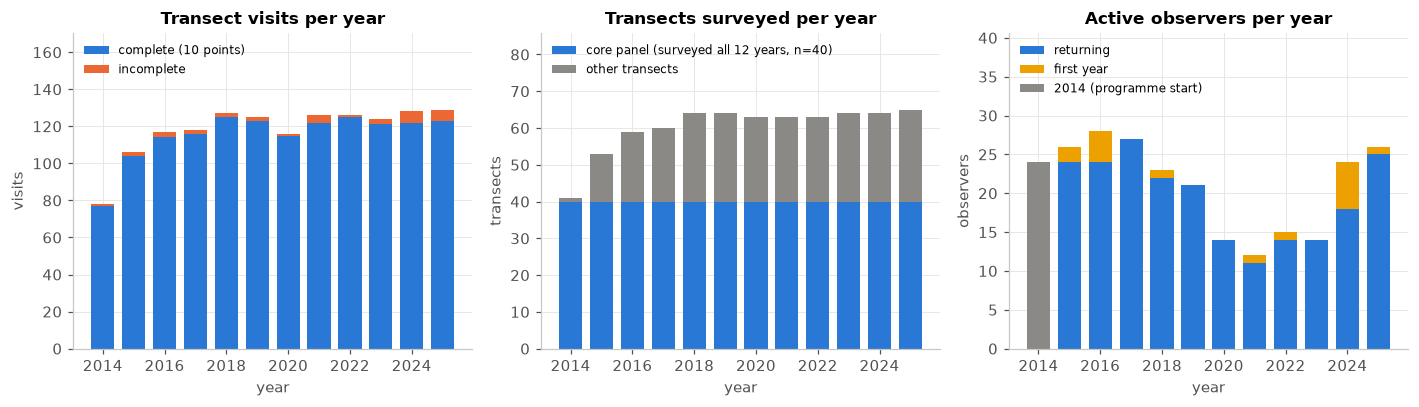

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
yrs = eff.index.values

ax = axes[0]
ax.bar(yrs, eff["complete_visits"], color=plots.PALETTE[0], width=0.75, label="complete (10 points)")
ax.bar(yrs, eff["visits"] - eff["complete_visits"], bottom=eff["complete_visits"],
       color=plots.PALETTE[1], width=0.75, label="incomplete")
ax.set(title="Transect visits per year", ylabel="visits", ylim=(0, eff["visits"].max() * 1.32))

ax = axes[1]
ax.bar(yrs, eff["core_transects"], color=plots.PALETTE[0], width=0.75, label=f"core panel (surveyed all 12 years, n={len(core)})")
ax.bar(yrs, eff["transects"] - eff["core_transects"], bottom=eff["core_transects"],
       color=plots.GREY, width=0.75, label="other transects")
ax.set(title="Transects surveyed per year", ylabel="transects", ylim=(0, eff["transects"].max() * 1.32))

ax = axes[2]
ret = (eff["observers"] - eff["new_observers"]).where(eff.index > 2014, 0)
new = eff["new_observers"].where(eff.index > 2014, 0)
ax.bar(yrs, ret, color=plots.PALETTE[0], width=0.75, label="returning")
ax.bar(yrs, new, bottom=ret, color=plots.PALETTE[3], width=0.75, label="first year")
ax.bar([2014], eff.loc[2014, "observers"], color=plots.GREY, width=0.75, label="2014 (programme start)")
ax.set(title="Active observers per year", ylabel="observers", ylim=(0, eff["observers"].max() * 1.45))

for ax in axes:
    ax.set_xlabel("year")
    ax.set_xticks(yrs[::2])
    ax.legend(loc="upper left", fontsize=8, ncol=1)
fig.tight_layout()
plots.savefig(fig, "fig01_effort_over_time")
plt.show()

**Reading.** 2014 is a ramp-up year (78 visits on 41 transects). Effort stabilises from
2016–2018 at 116–129 visits on 59–65 transects, almost all complete (10 points). A **core panel
of 40 transects was surveyed in every year**; it is the natural basis for robustness checks
against the changing set of sites. The observer pool shrank from 21–28 people (2014–2019) to
12–15 (2020–2023), then grew again with a wave of new observers in 2024. Raw annual totals are
therefore *not* comparable across years: every indicator in notebook 02 is expressed per unit of
effort (per point count or per visit) and modelled with transect and observer terms.

## 5. Effort in space: which transects, which habitats, which observers

The matrix below is the single most important picture of the sampling design: one row per
transect, one column per year. Cell shade = number of visits (0, 1, 2); a dot marks a year
in which the observer differs from the previous year's observer on that transect.

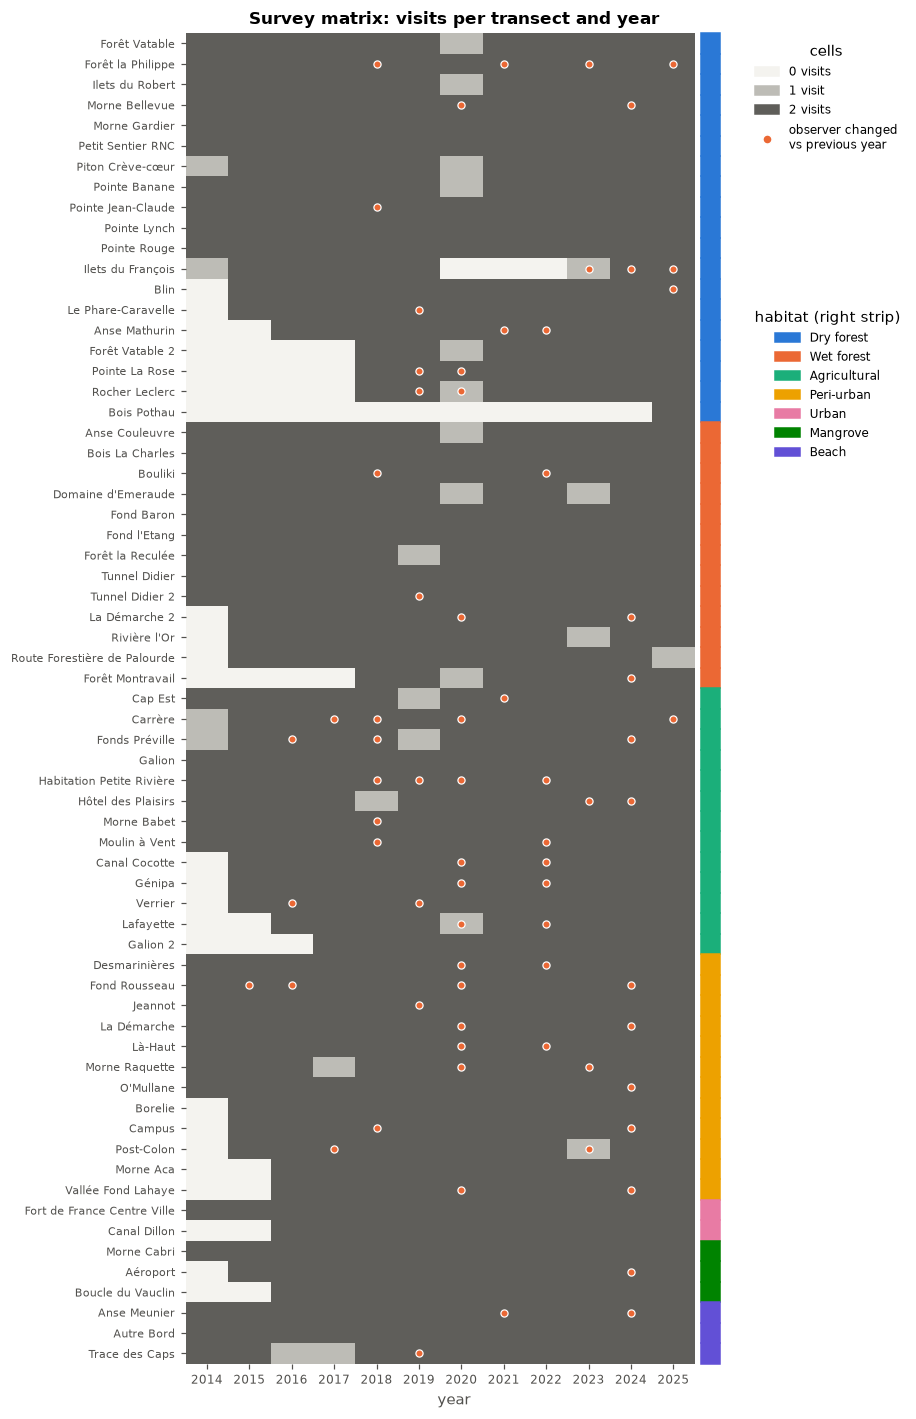

In [11]:
mat = visits.pivot_table(index="transect", columns="year", values="visit_id", aggfunc="size").fillna(0)
hab = visits.groupby("transect")["habitat"].first()
first_yr = visits.groupby("transect")["year"].min()
order = (pd.DataFrame({"hab": hab, "first": first_yr, "n": yrs_per_tr})
           .assign(hab_rank=lambda x: x["hab"].map({h: i for i, h in enumerate(plots.HABITAT_COLORS)}))
           .sort_values(["hab_rank", "first", "n"], ascending=[True, True, False]).index)
mat = mat.loc[order]

# observer change between consecutive surveyed years on the same transect
obs_tr_yr = visits.groupby(["transect", "year"])["observer"].agg(lambda s: s.mode().iloc[0]).unstack()
change = pd.DataFrame(False, index=obs_tr_yr.index, columns=obs_tr_yr.columns)
for tr, row in obs_tr_yr.iterrows():
    prev = None
    for yr, o in row.dropna().items():
        if prev is not None and o != prev:
            change.loc[tr, yr] = True
        prev = o
change = change.loc[order]

# Sequential single-hue (grey) shading for 0/1/2 visits, so that the habitat colours
# (categorical) and the observer-change markers stay unambiguous.
cmap = mcolors.ListedColormap(["#f4f3ef", "#bdbcb6", "#5f5e5a"])
fig, ax = plt.subplots(figsize=(8.5, 13))
ax.imshow(mat.values, aspect="auto", cmap=cmap, vmin=-0.5, vmax=2.5, interpolation="none")
yy, xx = np.where(change.reindex(columns=mat.columns, fill_value=False).values)
ax.scatter(xx, yy, s=22, color=plots.PALETTE[1], edgecolor="white", linewidth=0.8, zorder=3)
ncol = mat.shape[1]
for i, t in enumerate(mat.index):
    ax.add_patch(plt.Rectangle((ncol - 0.35, i - 0.5), 0.45, 1, color=plots.HABITAT_COLORS[hab[t]], clip_on=False))
ax.set_xlim(-0.5, ncol + 0.15)
ax.set_xticks(range(ncol), mat.columns, fontsize=8)
ax.set_yticks(range(mat.shape[0]), list(mat.index), fontsize=7)
ax.grid(False)
for sp_ in ax.spines.values():
    sp_.set_visible(False)
ax.set_xlabel("year")
ax.set_title("Survey matrix: visits per transect and year")
handles = [Patch(color=c, label=l) for c, l in zip(cmap.colors, ["0 visits", "1 visit", "2 visits"])]
handles += [Line2D([], [], marker="o", ls="", color=plots.PALETTE[1], markeredgecolor="white", markersize=6,
                   label="observer changed\nvs previous year")]
hab_handles = [Patch(color=c, label=h) for h, c in plots.HABITAT_COLORS.items()]
leg1 = ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.04, 1), fontsize=8, title="cells")
ax.add_artist(leg1)
ax.legend(handles=hab_handles, loc="upper left", bbox_to_anchor=(1.04, 0.80), fontsize=8, title="habitat (right strip)")
fig.tight_layout()
plots.savefig(fig, "fig02_survey_matrix")
plt.show()

In [12]:
n_changes = change.values.sum()
n_trans = int((mat > 0).values.sum() - mat.shape[0])  # year-to-year transitions
print(f"Observer changes on a transect between consecutive surveyed years: {n_changes} of {n_trans} transitions "
      f"({n_changes / n_trans:.0%})")
print(f"Transects ever surveyed by more than one observer: {(obs_tr_yr.nunique(axis=1) > 1).sum()} of {len(obs_tr_yr)}")
print("\nTransects by habitat (all / core panel):")
hab_tab = pd.DataFrame({"all": hab.value_counts(), "core": hab[hab.index.isin(core)].value_counts()}).fillna(0).astype(int)
print(hab_tab.to_string())

Observer changes on a transect between consecutive surveyed years: 73 of 658 transitions (11%)
Transects ever surveyed by more than one observer: 37 of 65

Transects by habitat (all / core panel):
              all  core
habitat                
Agricultural   13     8
Beach           3     3
Dry forest     19    11
Mangrove        3     1
Peri-urban     12     7
Urban           2     1
Wet forest     13     9


**Reading.** The panel imbalance comes almost entirely from transects **added** in 2015–2018,
not from transects dropped (only Ilets du François has a multi-year gap, 2020–2022). In 2020,
ten transects received only their second visit (May–June); this coincides with the COVID-19
lockdown in spring 2020 (hypothesis, external information). Observer changes on a given transect
are relatively rare (11 % of year-to-year transitions) but cluster in 2020 and 2024 — the
years in which the observer pool contracted and then expanded.

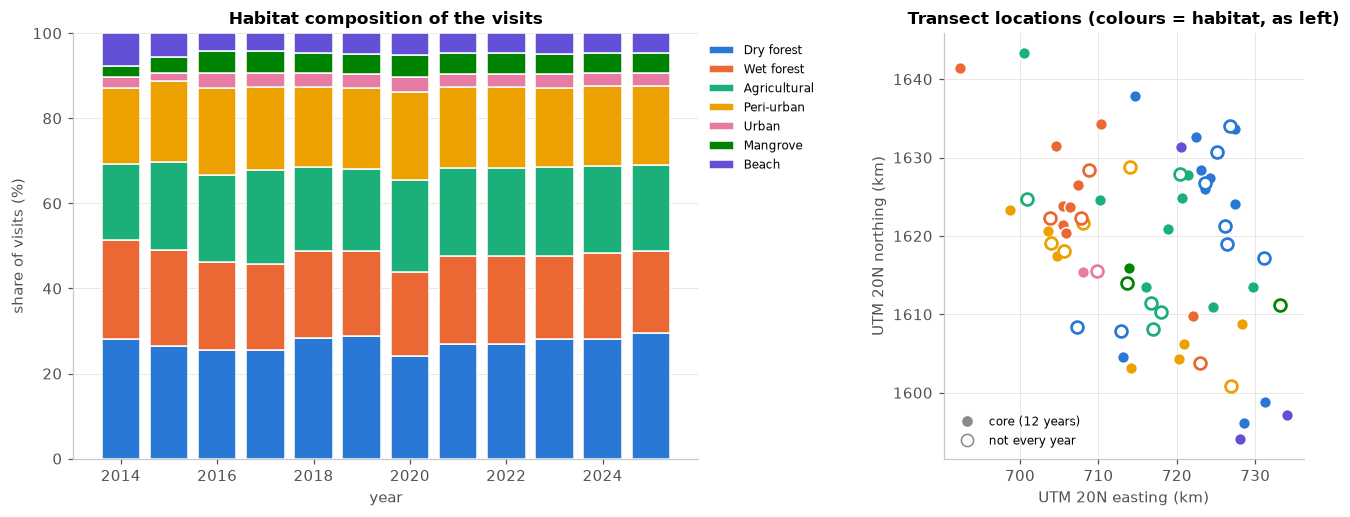

In [13]:
# Habitat composition of the effort, per year (share of visits)
hab_share = pd.crosstab(visits["year"], visits["habitat"], normalize="index")[list(plots.HABITAT_COLORS)]
loc = sites.groupby("transect")[["x_utm", "y_utm"]].mean() / 1000
loc = loc.join(hab).join(yrs_per_tr.rename("n_years"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
bottom = np.zeros(len(hab_share))
for h in hab_share.columns:
    ax.bar(hab_share.index, hab_share[h] * 100, bottom=bottom, color=plots.HABITAT_COLORS[h],
           width=0.8, label=h, edgecolor="white", linewidth=1)
    bottom += hab_share[h].values * 100
ax.set(title="Habitat composition of the visits", xlabel="year", ylabel="share of visits (%)", ylim=(0, 100))
ax.set_xticks(hab_share.index[::2])
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1), fontsize=8)

ax = axes[1]
for h, g in loc.groupby("habitat"):
    is_core = g.index.isin(core)
    ax.scatter(g.loc[is_core, "x_utm"], g.loc[is_core, "y_utm"], s=60, color=plots.HABITAT_COLORS[h],
               edgecolor="white", linewidth=1, zorder=3)
    ax.scatter(g.loc[~is_core, "x_utm"], g.loc[~is_core, "y_utm"], s=60, facecolor="white",
               edgecolor=plots.HABITAT_COLORS[h], linewidth=1.8, zorder=3)
ax.set(title="Transect locations (colours = habitat, as left)", xlabel="UTM 20N easting (km)",
       ylabel="UTM 20N northing (km)")
ax.set_aspect("equal")
ax.legend(handles=[Line2D([], [], marker="o", ls="", markerfacecolor=plots.GREY, markeredgecolor="white", markersize=8, label="core (12 years)"),
                   Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=plots.GREY, markersize=8, label="not every year")],
          loc="lower left", fontsize=8)
fig.tight_layout()
plots.savefig(fig, "fig03_habitat_and_space")
plt.show()

**Reading.** After 2015 the habitat mix of the effort is stable (≈27 % dry forest, 20 % wet
forest, 20 % agricultural, 19 % peri-urban), so composition shifts between habitats are unlikely
to drive trends after that date; 2014 differs (no agricultural/peri-urban newcomers yet). The
transects cover the whole island, but habitats are spatially clustered (wet forest in the
north-west, dry forest mostly in the east and south), so "habitat" and "region" cannot be
separated with these data.

## 6. Observers: concentration, attendance and longevity

Observer identity is a major nuisance variable for detection: hearing ability and species
knowledge differ between people. Three questions: do a few observers account for most of the
records? How regularly and for how long do observers take part? Does the observer mix change
over time?

In [14]:
visits = effort.add_observer_experience(visits)
n_rec_obs = rec.groupby("observer").size()
obs_sum = visits.groupby("observer").agg(
    visits=("visit_id", "size"), transects=("transect", "nunique"),
    first_year=("year", "min"), last_year=("year", "max"), years_active=("year", "nunique"),
    mentored_visits=("mentored", "sum"),
).sort_values("visits", ascending=False)
obs_sum["records"] = n_rec_obs.reindex(obs_sum.index).astype(int)
obs_sum["pct_records"] = (obs_sum["records"] / obs_sum["records"].sum() * 100).round(1)
obs_sum["span_years"] = obs_sum["last_year"] - obs_sum["first_year"] + 1
obs_sum["attendance"] = (obs_sum["years_active"] / obs_sum["span_years"]).round(2)  # share of years present within own span
obs_sum["mean_richness_complete"] = visits[visits["complete"]].groupby("observer")["richness"].mean().round(1)
# Observers are shown under anonymous codes (O01 = most visits) in tables and figures.
obs_code = {o: f"O{i + 1:02d}" for i, o in enumerate(obs_sum.index)}
visits["observer_code"] = visits["observer"].map(obs_code)
obs_sum.index = obs_sum.index.map(obs_code)
obs_sum.index.name = "observer"
obs_sum.to_csv(C.RES_DIR / "table06_observer_summary.csv")

cum = obs_sum["records"].sort_values(ascending=False).cumsum() / obs_sum["records"].sum()
k50, k80 = int((cum < 0.5).sum() + 1), int((cum < 0.8).sum() + 1)
print(f"{len(obs_sum)} observer units. {k50} observer(s) account for 50 % of all records, {k80} for 80 %.")
print(f"The single most active observer: {obs_sum['pct_records'].iloc[0]} % of records.")
print(f"Longevity: {(obs_sum['years_active'] >= 10).sum()} observers active in >= 10 of 12 years; "
      f"{(obs_sum['years_active'] <= 2).sum()} active in <= 2 years. "
      f"Median attendance within own active span: {obs_sum['attendance'].median():.2f}")
obs_sum[["visits", "records", "pct_records", "transects", "first_year", "last_year", "years_active",
         "attendance", "mean_richness_complete"]].head(15)

40 observer units. 3 observer(s) account for 50 % of all records, 13 for 80 %.
The single most active observer: 37.4 % of records.
Longevity: 12 observers active in >= 10 of 12 years; 9 active in <= 2 years. Median attendance within own active span: 1.00


,visits,records,pct_records,transects,first_year,last_year,years_active,attendance,mean_richness_complete
observer,,,,,,,,,
O01,483,42050,37.4,43,2014,2025,12,1.00,20.2
O02,101,6838,6.1,6,2014,2025,12,1.00,17.7
O03,100,8120,7.2,6,2014,2025,10,0.83,21.0
O04,90,5053,4.5,4,2014,2025,12,1.00,15.1
O05,87,7331,6.5,5,2014,2025,12,1.00,19.0
O06,69,4228,3.8,4,2014,2025,12,1.00,14.9
O07,62,3398,3.0,3,2014,2025,12,1.00,14.1
O08,34,2655,2.4,2,2014,2025,9,0.75,17.1
O09,34,3060,2.7,2,2014,2025,12,1.00,20.3


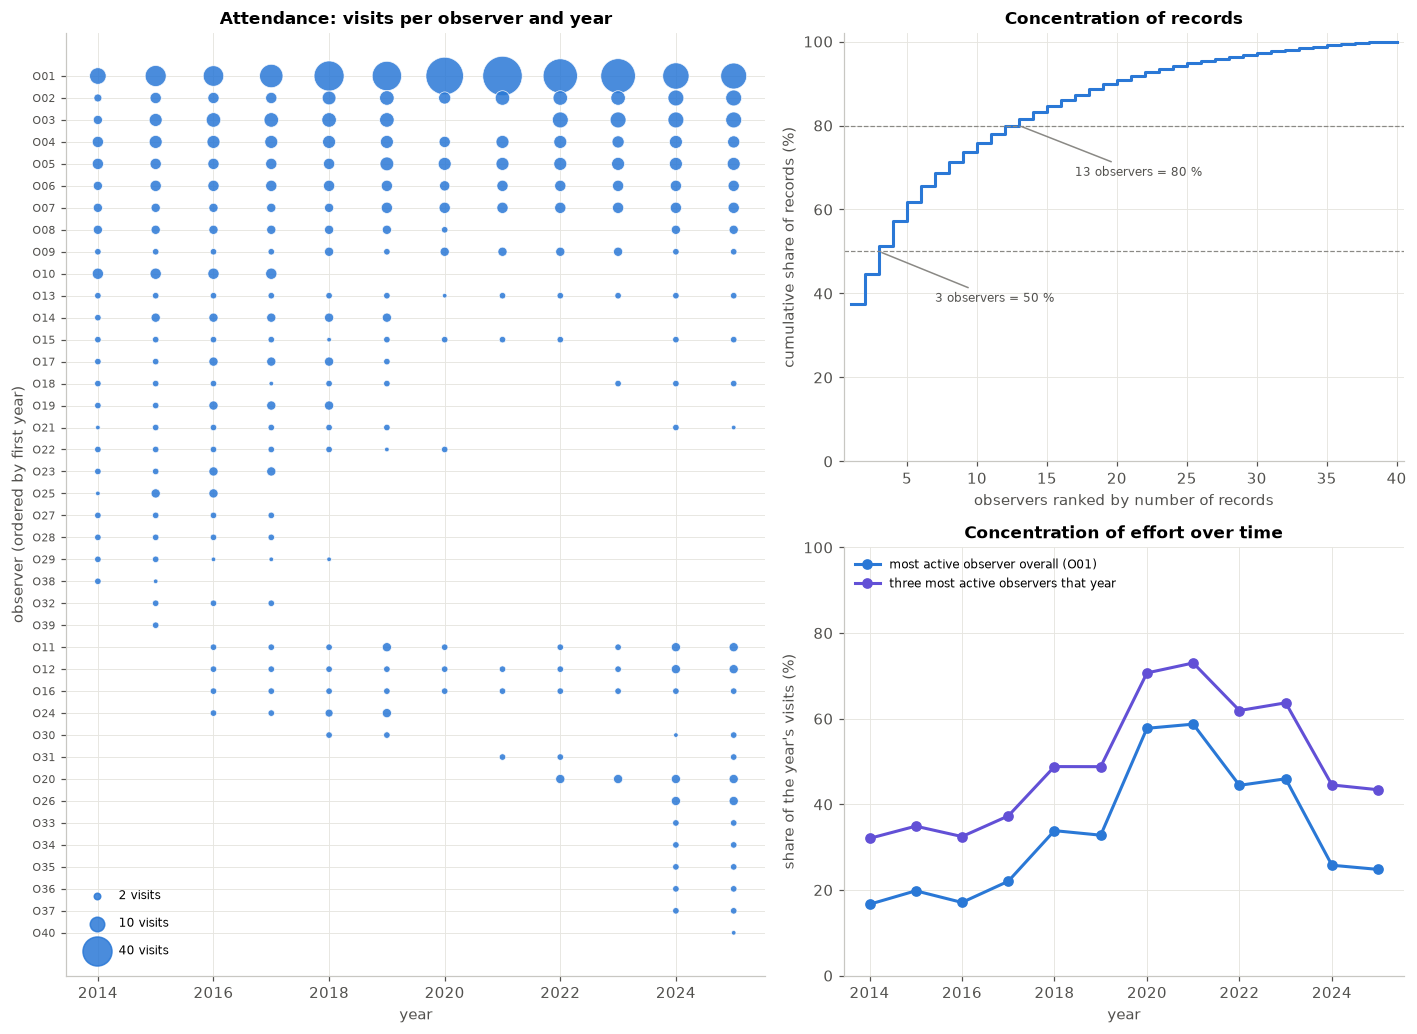

In [15]:
# Attendance matrix (observer x year, dot area = visits) and concentration of the records
att = visits.pivot_table(index="observer_code", columns="year", values="visit_id", aggfunc="size").fillna(0)
order_obs = obs_sum.sort_values(["first_year", "visits"], ascending=[True, False]).index
att = att.loc[order_obs]
share_top = visits.groupby("year")["observer"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
share_named = visits.assign(t=visits["observer_code"].eq("O01")).groupby("year")["t"].mean()
share_top3 = visits.groupby("year")["observer"].agg(lambda s: s.value_counts(normalize=True).iloc[:3].sum())

fig = plt.figure(figsize=(13, 9.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1], height_ratios=[1, 1])
ax = fig.add_subplot(gs[:, 0])
yy, xx = np.nonzero(att.values)
ax.scatter(att.columns.values[xx], yy, s=att.values[yy, xx] * 9, color=plots.PALETTE[0], alpha=0.85,
           edgecolor="white", linewidth=0.5)
ax.set_yticks(range(len(att)), list(att.index), fontsize=7)
ax.invert_yaxis()
ax.set_xticks(yrs[::2])
ax.set(title="Attendance: visits per observer and year", xlabel="year", ylabel="observer (ordered by first year)")
for n in [2, 10, 40]:
    ax.scatter([], [], s=n * 9, color=plots.PALETTE[0], alpha=0.85, label=f"{n} visits")
ax.legend(loc="lower left", fontsize=8, labelspacing=1.2, borderpad=1)

ax = fig.add_subplot(gs[0, 1])
ax.step(np.arange(1, len(cum) + 1), cum.values * 100, where="post", color=plots.PALETTE[0])
ax.axhline(50, color=plots.GREY, lw=0.8, ls="--"); ax.axhline(80, color=plots.GREY, lw=0.8, ls="--")
ax.set(title="Concentration of records", xlabel="observers ranked by number of records",
       ylabel="cumulative share of records (%)", ylim=(0, 102), xlim=(0.5, len(cum) + 0.5))
ax.annotate(f"{k50} observers = 50 %", (k50, 50), xytext=(k50 + 4, 38), fontsize=8, color=plots.INK2,
            arrowprops=dict(arrowstyle="-", color=plots.GREY))
ax.annotate(f"{k80} observers = 80 %", (k80, 80), xytext=(k80 + 4, 68), fontsize=8, color=plots.INK2,
            arrowprops=dict(arrowstyle="-", color=plots.GREY))

ax = fig.add_subplot(gs[1, 1])
ax.plot(yrs, share_named * 100, marker="o", color=plots.PALETTE[0], label="most active observer overall (O01)")
ax.plot(yrs, share_top3 * 100, marker="o", color=plots.PALETTE[6], label="three most active observers that year")
ax.set(title="Concentration of effort over time", ylabel="share of the year's visits (%)",
       xlabel="year", ylim=(0, 100))
ax.set_xticks(yrs[::2])
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plots.savefig(fig, "fig06_observers")
plt.show()

**Reading.** The effort is highly concentrated: a handful of observers produce most of the
records, and one observer alone more than a third (37 %). The core of the programme is a small group of
long-term observers present in (almost) every year since 2014, complemented by many
short-term participants. Crucially, the **observer mix changes over time**: the most active
observer made 17 % of the visits in 2014, **58–59 % in 2020–2021**, and 25 % in 2024–2025, when a
wave of new observers joined. If observers differ in how many birds they detect, a change in the
observer mix alone can create an apparent trend.

In [16]:
# Is the observer mix related to the raw abundance curve? (descriptive, not causal)
ipc = eff["individuals_per_point_count"]
print(pd.DataFrame({"top observer share of visits": share_named.round(2),
                    "raw individuals per point count": ipc}).T.to_string())
r_ = np.corrcoef(share_named.values, ipc.values)[0, 1]
print(f"\nAcross the 12 years, correlation between the two series: {r_:.2f} (n = 12, descriptive only)")

year                              2014   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024  2025
top observer share of visits      0.17    0.2   0.17   0.22   0.34   0.33   0.58   0.59   0.44   0.46   0.26  0.25
raw individuals per point count  14.16  16.41  16.52  17.58  15.79  16.87  19.04  19.08  19.22  18.02  16.86  16.4

Across the 12 years, correlation between the two series: 0.81 (n = 12, descriptive only)


The raw abundance curve peaks in exactly the years when one observer dominated. This is not
proof of an observer effect (other things changed in the same years, e.g. the pandemic), but it
shows that **observer identity and year are partly confounded**. In the regression framework of
notebook 02 this is an *omitted-variable bias* risk: a trend model without observer terms may
attribute observer differences to time. We therefore compare specifications with and without
observer effects / observer experience.

Observer **experience** is recorded for every visit (`obs_prev_seasons`: number of earlier years
the observer took part in). Its distribution per year:

In [17]:
exp_tab = visits.groupby("year").agg(
    pct_visits_by_first_year_observers=("obs_first_season", lambda s: round(s.mean() * 100, 1)),
    median_prev_years=("obs_prev_seasons", "median"))
print("(2014 is left-censored: every observer is 'new' at programme start.)")
r_exp = np.corrcoef(visits["year"], visits["obs_prev_seasons"])[0, 1]
print(f"Visit-level correlation between year and observer experience: {r_exp:.2f} "
      f"(variance inflation factor of year if both enter a model: {1 / (1 - r_exp ** 2):.1f})")
exp_tab.T

(2014 is left-censored: every observer is 'new' at programme start.)
Visit-level correlation between year and observer experience: 0.85 (variance inflation factor of year if both enter a model: 3.5)


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pct_visits_by_first_year_observers,100.0,3.8,6.8,0.0,1.6,0.0,0.0,1.6,3.2,0.0,10.9,0.8
median_prev_years,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0


**Reading — experience is almost a proxy for time.** Because the core observers stayed for all
12 years, the median experience simply grows by one each year, and experience correlates at
0.85 with year. A model containing both cannot cleanly separate "birds changed" from "observers
became more experienced": the year coefficient stays estimable (newer observers break the
collinearity) but its variance is inflated about 3.5-fold. This is a concrete instance of the
bias–variance trade-off that notebook 02 must discuss: leaving experience out risks bias,
putting it in costs precision. Observer *identity* (fixed effects) is identified differently —
through the 73 within-transect observer changes — and is the main alternative specification.

## 7. Survey timing

Detectability changes over the breeding season (singing activity) and over the morning, so the
calendar of the surveys should be stable across years for raw annual values to be comparable.

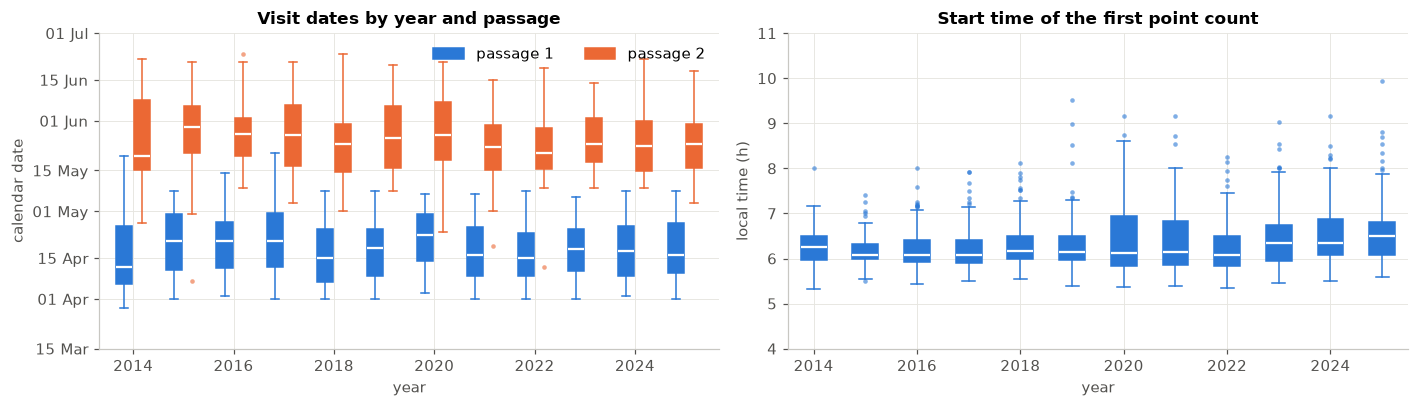

In [18]:
p1 = point_visits.merge(visits[["visit_id", "doy", "same_day_passages"]], on="visit_id")
first_pt = p1.sort_values("point").groupby("visit_id").first()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
for p, col, off in [(1, plots.PALETTE[0], -0.18), (2, plots.PALETTE[1], 0.18)]:
    vv = visits[visits["passage"] == p]
    data = [vv.loc[vv["year"] == y, "doy"].values for y in yrs]
    bp = ax.boxplot(data, positions=yrs + off, widths=0.32, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", markersize=3, markerfacecolor=col, markeredgecolor="none", alpha=0.6),
                    medianprops=dict(color="white", linewidth=1.5), whiskerprops=dict(color=col),
                    capprops=dict(color=col), boxprops=dict(facecolor=col, edgecolor=col))
ticks = pd.to_datetime(["2021-03-15", "2021-04-01", "2021-04-15", "2021-05-01", "2021-05-15", "2021-06-01", "2021-06-15", "2021-07-01"])
ax.set_yticks(ticks.dayofyear, ticks.strftime("%d %b"))
ax.set_xticks(yrs[::2], yrs[::2])
ax.set(title="Visit dates by year and passage", xlabel="year", ylabel="calendar date")
ax.legend(handles=[Patch(color=plots.PALETTE[0], label="passage 1"), Patch(color=plots.PALETTE[1], label="passage 2")], loc="upper right", ncol=2)

ax = axes[1]
data = [first_pt.loc[first_pt["year"] == y, "start_min"].dropna().values / 60 for y in yrs]
ax.boxplot(data, positions=yrs, widths=0.5, patch_artist=True,
           flierprops=dict(marker="o", markersize=3, markerfacecolor=plots.PALETTE[0], markeredgecolor="none", alpha=0.6),
           medianprops=dict(color="white", linewidth=1.5), whiskerprops=dict(color=plots.PALETTE[0]),
           capprops=dict(color=plots.PALETTE[0]), boxprops=dict(facecolor=plots.PALETTE[0], edgecolor=plots.PALETTE[0]))
ax.set_xticks(yrs[::2], yrs[::2])
ax.set(title="Start time of the first point count", xlabel="year", ylabel="local time (h)", ylim=(4, 11))
fig.tight_layout()
plots.savefig(fig, "fig04_survey_timing")
plt.show()

**Reading.** The calendar is stable: passage 1 is centred on mid-April, passage 2 on late May,
with no drift of the medians across years, so seasonal timing is unlikely to create a
trend. First points start around 06:00–06:30; median start times are slightly later in
2023–2025, which could lower detectability marginally (dawn chorus). Day-of-year and start time
are kept as covariates.

In [19]:
gap = visits.groupby(["transect", "year"])["doy"].agg(lambda s: s.max() - s.min() if len(s) == 2 else np.nan)
late = (first_pt["start_min"] > 9 * 60).sum()
dur = visits.loc[visits["complete"], "duration_min"]
print(f"Days between passage 1 and 2 (same transect & year): median {gap.median():.0f}, IQR {gap.quantile(.25):.0f}-{gap.quantile(.75):.0f}")
print(f"Transect-years recorded with both passages on the same date (flagged): {visits['same_day_passages'].sum() // 2}")
print(f"Visits whose first point started after 09:00: {late} of {len(first_pt)}")
print(f"Duration point 1 -> point 10 (complete visits): median {dur.median():.0f} min, "
      f"> 180 min (implausible, likely time typos): {(dur > 180).sum()}")

Days between passage 1 and 2 (same transect & year): median 36, IQR 33-41
Transect-years recorded with both passages on the same date (flagged): 7
Visits whose first point started after 09:00: 6 of 1420
Duration point 1 -> point 10 (complete visits): median 88 min, > 180 min (implausible, likely time typos): 10


## 8. Weather during the surveys

Weather was recorded **per point** (it changes between points of the same visit in 38 % (clouds)
and 48 % (wind) of visits, see the check below), so it can enter models at point level. The table shows, per
year, the share of point counts made in non-ideal conditions.

In [20]:
pw = records.drop_duplicates(["visit_id", "point"])[["visit_id", "point", "year", "clouds", "rain", "wind", "visibility"]]
wx = pw.groupby("year").agg(
    point_counts=("point", "size"),
    rain_pct=("rain", lambda s: (s >= 2).mean() * 100),
    wind_mod_strong_pct=("wind", lambda s: (s == 3).mean() * 100),
    overcast_pct=("clouds", lambda s: (s == 3).mean() * 100),
    poor_visibility_pct=("visibility", lambda s: (s == 3).mean() * 100),
).round(1)
wx.to_csv(C.RES_DIR / "table04_weather_by_year.csv")
print("Share of point counts (%) in each condition:")
wx

Share of point counts (%) in each condition:


,point_counts,rain_pct,wind_mod_strong_pct,overcast_pct,poor_visibility_pct
year,,,,,
2014,778,3.3,4.2,17.4,0.4
2015,1055,3.4,6.5,16.9,10.8
2016,1161,4.5,6.7,23.6,10.0
2017,1168,5.0,8.4,32.4,34.0
2018,1261,3.7,8.8,18.8,6.9
2019,1246,4.3,3.3,23.7,5.4
2020,1158,1.2,5.8,18.6,2.2
2021,1254,2.4,5.1,20.5,3.5
2022,1259,4.2,7.6,27.6,3.3


In [21]:
# Does weather relate to counts? Descriptive only (confounded with site/year; modelled in notebook 02).
pv_w = point_visits.merge(pw[["visit_id", "point", "rain", "wind", "clouds", "visibility"]], on=["visit_id", "point"])
rows = []
for v in ["rain", "wind", "clouds", "visibility"]:
    g = pv_w.groupby(v)["n_ind"].agg(["size", "mean"])
    for lvl, r in g.iterrows():
        rows.append({"variable": v, "code": int(lvl), "label": C.WEATHER_LABELS[v][int(lvl)],
                     "point_counts": int(r["size"]), "mean_individuals": round(r["mean"], 2)})
pd.DataFrame(rows).set_index(["variable", "code"])

label  point_counts  mean_individuals
variable   code                                                 
rain       1                none         13658             17.40
           2             drizzle           435             13.35
           3             showers            34              9.62
wind       1                none          8932             17.56
           2               light          4312             17.02
           3     moderate/strong           880             15.44
clouds     1              0-33 %          3976             15.47
           2             33-66 %          7036             17.85
           3            66-100 %          3114             18.21
visibility 1                good          9455             16.93
           2            moderate          3738             17.93
           3                poor           933             17.90

In [22]:
# Checks behind the reading below: is weather constant within a visit, and is visibility observer-specific?
chg = pw.groupby("visit_id")[["clouds", "wind", "rain", "visibility"]].nunique().gt(1).mean().mul(100).round(1)
print("Share of visits in which the code changes between points (%):", chg.to_dict())
pwo = pw.merge(visits[["visit_id", "observer"]], on="visit_id")
p17 = pwo[(pwo["year"] == 2017) & (pwo["visibility"] == 3)]
top2 = p17["observer"].value_counts().head(2).sum()
print(f"2017: {len(p17)} point counts coded 'poor visibility' ({len(p17) / (pwo['year'] == 2017).sum():.0%}); "
      f"the two observers with most of them account for {top2 / len(p17):.0%}")
n_o = pwo.groupby("observer").size()
mod = pwo.groupby("observer")["visibility"].apply(lambda x: (x == 2).mean() * 100)[n_o >= 100]
print(f"Share of point counts coded 'moderate' visibility, observers with >= 100 point counts: "
      f"{mod.min():.1f} % to {mod.max():.1f} % (n = {len(mod)} observers)")

Share of visits in which the code changes between points (%): {'clouds': 37.8, 'wind': 47.5, 'rain': 10.9, 'visibility': 33.2}
2017: 397 point counts coded 'poor visibility' (34%); the two observers with most of them account for 50%
Share of point counts coded 'moderate' visibility, observers with >= 100 point counts: 0.5 % to 65.5 % (n = 24 observers)


**Reading.** Most counts are made in good conditions (rain at ≤ 5 % of point counts each
year). Counts drop under rain (17.4 → 13.4 → 9.6 individuals) and strong wind (17.6 → 15.4),
as expected from reduced detectability. Visibility is **not a reliable covariate**: two observers
account for half of the 34 % "poor visibility" in 2017, and observers use the scale very
differently overall (from below 1 % to about 66 % of their points coded "moderate"), i.e. the
code is largely observer-specific. Rain and wind are used as point-level covariates; visibility is not.

## 9. Counts and species

Distribution of the response variables that later indicators are built on.

In [23]:
pc = point_visits["n_ind"]
vc = visits.loc[visits["complete"], "n_ind"]
print(f"Individuals per 5-min point count: mean {pc.mean():.2f}, variance {pc.var():.1f} "
      f"(variance/mean = {pc.var() / pc.mean():.1f}), median {pc.median():.0f}, max {pc.max():.0f}, "
      f"zeros {(pc == 0).mean():.2%}")
print(f"Species per point count: mean {point_visits['richness'].mean():.2f}, variance {point_visits['richness'].var():.2f}")
print(f"Individuals per complete visit: mean {vc.mean():.1f}, median {vc.median():.0f}, max {vc.max():.0f}")
print(f"Species per complete visit: mean {visits.loc[visits['complete'], 'richness'].mean():.1f}, "
      f"range {visits.loc[visits['complete'], 'richness'].min():.0f}-{visits.loc[visits['complete'], 'richness'].max():.0f}")

Individuals per 5-min point count: mean 17.26, variance 118.0 (variance/mean = 6.8), median 15, max 210, zeros 0.01%
Species per point count: mean 7.83, variance 6.96
Individuals per complete visit: mean 171.8, median 161, max 699
Species per complete visit: mean 18.8, range 8-28


In [24]:
big = rec.nlargest(10, "count")[["year", "transect", "point", "species", "status", "count"]]
print("Largest single records (one species at one point):")
big

Largest single records (one species at one point):


,year,transect,point,species,status,count
107369,2025,Ilets du François,5,Sterne de Dougall,Seabird,200.0
107428,2025,Ilets du Robert,4,Sterne fuligineuse,Seabird,200.0
35135,2018,Fonds Préville,7,Héron garde-bœuf,Exotic (natural coloniser),152.0
56475,2020,Ilets du Robert,8,Sterne fuligineuse,Seabird,150.0
76746,2022,Ilets du Robert,3,Sterne fuligineuse,Seabird,150.0
65798,2021,Ilets du Robert,8,Sterne de Dougall,Seabird,132.0
12588,2015,Fort de France Centre Ville,7,Pigeon biset domestique,Exotic (human-introduced),123.0
48576,2019,Fort de France Centre Ville,10,Pigeon biset domestique,Exotic (human-introduced),121.0
65844,2021,Ilets du Robert,4,Sterne fuligineuse,Seabird,120.0
53594,2020,Canal Cocotte,3,Héron garde-bœuf,Exotic (natural coloniser),102.0


**Reading.** Counts per point are strongly right-skewed and **overdispersed** (variance/mean ≈ 6.8).
The heaviest tails come from **seabird colonies** on two islets and **feral pigeons** in
Fort-de-France: a handful of records can move annual means, so the community abundance index
excludes seabirds and fly-overs, and is checked for sensitivity to these records.

**Which scale for a linear model?** Notebook 02 fits linear regressions to a per-visit
abundance index (individuals per point count). The check below shows that, across transects,
the spread of this index grows in proportion to its mean on the raw scale but is constant on
the log scale, and that the log removes the skewness. A linear model on **log(index)** therefore
has approximately constant residual variance, and its year coefficient reads as a
**percentage change per year**.

In [25]:
vc_ = visits[visits["complete"]].assign(y=lambda x: x["n_ind"] / x["n_points"])
by_tr = vc_.groupby("transect")["y"].agg(["mean", "std"])
by_tr["sd_log"] = vc_.assign(l=np.log(vc_["y"])).groupby("transect")["l"].std()
print(f"Across transects: corr(mean, SD) on raw scale = {np.corrcoef(by_tr['mean'], by_tr['std'])[0, 1]:.2f}; "
      f"corr(mean, SD of log) = {np.corrcoef(by_tr['mean'], by_tr['sd_log'])[0, 1]:.2f}")
print(f"Skewness of the per-visit index: raw {vc_['y'].skew():.2f}, log {np.log(vc_['y']).skew():.2f}; "
      f"minimum {vc_['y'].min():.1f} (no zeros, so the log needs no offset)")

Across transects: corr(mean, SD) on raw scale = 0.65; corr(mean, SD of log) = 0.09
Skewness of the per-visit index: raw 1.75, log 0.05; minimum 4.7 (no zeros, so the log needs no offset)


In [26]:
sp_freq = (rec[rec["is_species"]]
           .groupby(["species", "name_sci", "status", "status_group"], dropna=False)
           .agg(records=("count", "size"), individuals=("count", "sum"),
                visits_detected=("visit_id", "nunique"))
           .reset_index())
sp_freq["pct_visits"] = (sp_freq["visits_detected"] / len(visits) * 100).round(1)
sp_freq["years_detected"] = sp_freq["species"].map(rec.groupby("species")["year"].nunique())
sp_freq = sp_freq.sort_values("visits_detected", ascending=False).reset_index(drop=True)
sp_freq.to_csv(C.RES_DIR / "table05_species_frequency.csv", index=False)
print(f"{len(sp_freq)} species; detected in >= 50% of visits: {(sp_freq['pct_visits'] >= 50).sum()}; "
      f"in < 1% of visits: {(sp_freq['pct_visits'] < 1).sum()}")
print(sp_freq.groupby("status_group", dropna=False).agg(species=("species", "size"),
      individuals=("individuals", "sum")).assign(share_ind_pct=lambda x: (x.individuals / x.individuals.sum() * 100).round(1)).to_string())

83 species; detected in >= 50% of visits: 15; in < 1% of visits: 23
              species  individuals  share_ind_pct
status_group                                     
Endemic            15      34408.0           14.2
Exotic             19      33650.0           13.9
Migrant            22       2520.0            1.0
Native             19     168742.0           69.7
Seabird             8       2783.0            1.1


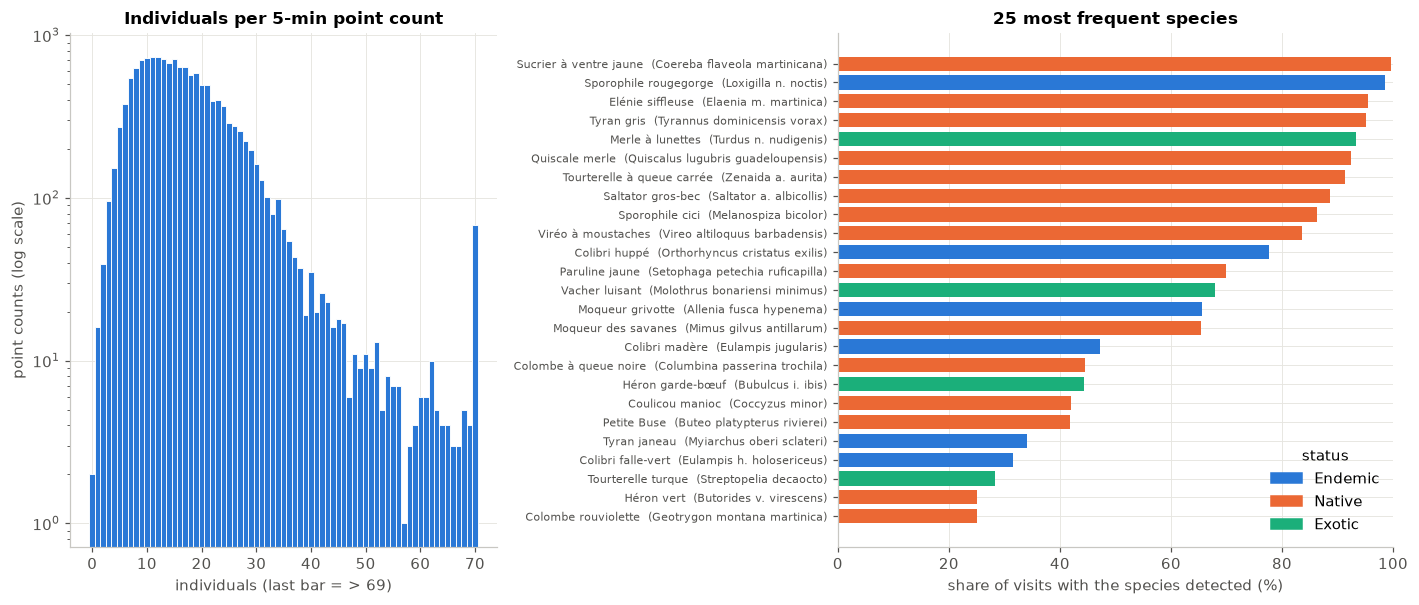

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
mx = int(np.percentile(pc, 99.5))
ax.hist(pc.clip(upper=mx + 1), bins=np.arange(0, mx + 3) - 0.5, color=plots.PALETTE[0], edgecolor="white", linewidth=0.6)
ax.set_yscale("log")
ax.set(title="Individuals per 5-min point count", xlabel=f"individuals (last bar = > {mx})", ylabel="point counts (log scale)")

ax = axes[1]
top = sp_freq.head(25).iloc[::-1]
ax.barh(top["species"] + "  (" + top["name_sci"].fillna("") + ")", top["pct_visits"],
        color=[plots.STATUS_COLORS.get(s, plots.GREY) for s in top["status_group"]], height=0.75)
ax.set(title="25 most frequent species", xlabel="share of visits with the species detected (%)", xlim=(0, 100))
ax.tick_params(axis="y", labelsize=7.5)
ax.legend(handles=[Patch(color=c, label=s) for s, c in plots.STATUS_COLORS.items() if s in set(top["status_group"])],
          loc="lower right", title="status")
fig.tight_layout()
plots.savefig(fig, "fig05_counts_and_species")
plt.show()

**Reading.** 83 species were identified, but the community is dominated by a few: 15 species
are detected in at least half of all visits (Bananaquit *Coereba flaveola* in virtually every
visit), while 23 appear in fewer than 1 % of visits. Native species make up ~70 % of
individuals, Lesser Antillean / Martinique endemics ~14 %, and exotics ~14 %. Rare species carry
almost no information about trends, which guides species selection in notebook 03.

## 10. Detection mode and distance

Most birds are **heard**, not seen. The heard/seen split and the distance composition are
sensitive to observer skill (hearing, song knowledge), so a shift over time could reflect a
change of observers rather than of birds. These are tracked as a *sampling* indicator.

In [28]:
det = rec.groupby("year")[C.DETAIL_COLS + ["count"]].sum()
det_share = pd.DataFrame({
    "heard_pct": det[C.AUD_COLS].sum(axis=1) / det["count"] * 100,
    **{f"{b}_pct": det[cols].sum(axis=1) / det["count"] * 100 for b, cols in C.DIST_BANDS.items()},
}).round(1)
tot = rec[C.DETAIL_COLS].sum()
print(f"Overall: {tot[C.AUD_COLS].sum() / tot.sum():.1%} of individuals heard only; "
      f"{(tot['aud_lt25'] + tot['vis_lt25'] + tot['aud_25_50'] + tot['vis_25_50']) / tot.sum():.1%} within 50 m; "
      f"fly-overs = {rec['flight'].sum() / (rec['flight'].sum() + rec['count'].sum()):.1%} of all individuals")
det_share

Overall: 60.4% of individuals heard only; 91.0% within 50 m; fly-overs = 1.4% of all individuals


,heard_pct,<25 m_pct,25-50 m_pct,50-100 m_pct,>100 m_pct
year,,,,,
2014,55.9,67.8,21.0,8.2,2.9
2015,54.5,68.0,22.6,7.5,1.8
2016,56.7,69.5,21.1,6.3,3.1
2017,59.0,72.6,20.3,5.0,2.1
2018,57.2,73.8,18.4,5.5,2.3
2019,59.1,71.9,20.1,4.8,3.1
2020,63.9,75.3,18.8,2.4,3.5
2021,59.3,74.8,18.3,2.9,4.1
2022,62.9,70.7,20.4,5.2,3.7


**Reading.** 60 % of individuals are detected by ear only and 91 % within 50 m. Both shares
**drift over time**: the heard-only share rises from ~56 % (2014–2016) to 64 % (2023–2025), and
the share beyond 100 m from ~3 % (2014–2016) to 5–7 % (2023–2025). Bird song does not change; these drifts point to a
change in the detection process (observer turnover, training), which reinforces the need to
separate detection from abundance — e.g. by repeating the abundance analysis on birds within
50 m only.

## 11. Save the clean tables

In [29]:
records.to_csv(C.PROCESSED_DIR / "records.csv.gz", index=False)
visits.to_csv(C.PROCESSED_DIR / "visits.csv", index=False)
point_visits.to_csv(C.PROCESSED_DIR / "point_visits.csv.gz", index=False)
species_tbl.to_csv(C.PROCESSED_DIR / "species.csv", index=False)
sites.to_csv(C.PROCESSED_DIR / "sites.csv", index=False)
for f in sorted(C.PROCESSED_DIR.iterdir()):
    print(f"{f.name:22s} {f.stat().st_size / 1e6:6.2f} MB")

point_visits.csv.gz      0.17 MB
records.csv.gz           2.00 MB
sites.csv                0.03 MB
species.csv              0.01 MB
visits.csv               0.29 MB


## 12. Summary and implications for the next steps

Main facts established in this notebook (all traceable to the outputs above):

* **Coverage.** 29 March 2014 – 18 June 2025 after cleaning (no 2012–2013 records). 65 transects × 10 points,
  1,420 transect visits (1,387 complete), 14,128 five-minute point counts, 243,856 individuals,
  83 species, 40 observer units.
* **Data quality.** Name variants, 25 double-entered visits (mostly 2016), drag-filled or
  mistyped dates, swapped passage labels and broken total formulas were repaired by explicit
  rules (`outputs/results/table02_cleaning_log.csv`). Without these fixes, 2016 effort and counts and
  2025 effort would be badly inflated.
* **Effort is not constant.** 2014 is a ramp-up year; transects were added until 2018; a core
  panel of 40 transects is complete for all 12 years. 2020 lost ten first visits (probably the
  COVID-19 lockdown).
* **Observers.** Records are concentrated on few people, and the **observer mix changes over
  time** in step with the raw abundance curve (risk of omitted-variable bias in trends).
* **Detection drifts**: more birds heard and more detected far away in recent years.
* **Scale.** The per-visit abundance index is multiplicative (SD ∝ mean): it is modelled on the
  log scale.

Consequences for notebook 02 onwards:

1. **Standardised abundance index** = total individuals / total point counts surveyed (per year,
   per species or for the community), also shown as a **base-100 index** (2014 = 100). Absences
   are true zeros: the denominator is *all* surveyed points, not the points where a species was
   seen.
2. **Annual estimates with confidence intervals** from a **transect-level cluster bootstrap**
   (points and visits of one transect are not independent).
3. **Global rate of change** from **linear regressions on log(index)**, compared across
   specifications of increasing complexity: simple trend → + transect (which sites were surveyed)
   and survey conditions → + observer identity or experience. Models are compared and criticised
   with goodness-of-fit, residual diagnostics, out-of-sample (cross-validated) error and the
   bias–variance trade-off; how much the year coefficient moves between specifications measures
   the effort/observer bias of the naive trend.
4. Robustness: core panel only; birds within 50 m; seabirds excluded.